In [1]:
# x 0.35
# z 0.45
import torch
import numpy as np
import trimesh as tm

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def visualize_point_cloud_matplotlib(points, color='b', size=1):
    """
    使用matplotlib可视化点云
    points: torch.Tensor of shape (N, 3)
    """
    if isinstance(points, torch.Tensor):
        points = points.cpu().numpy()
    
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], 
               c=color, s=size, alpha=0.6)
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    plt.show()


In [6]:
path = "meshes/collision/test.stl"
path = "meshes/leaphand/dip.stl"
mesh = tm.load(path)
# mesh.show()

In [7]:
mesh.show()

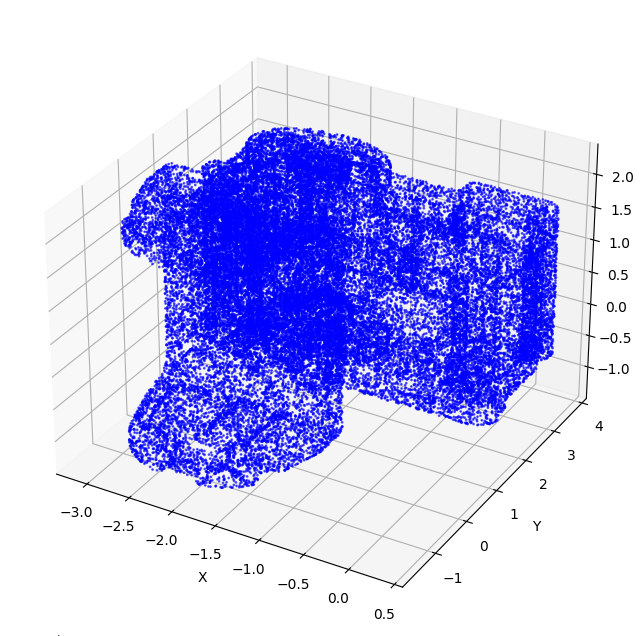

In [4]:
mesh.apply_scale(1e-3)
pts = torch.tensor(mesh.sample(50000, return_index=False))
pts[:, 2] = -pts[:, 2]

visualize_point_cloud_matplotlib(pts)
pts_x = pts[:, 0]
pts_y = pts[:, 1]
pts_z = pts[:, 2]

x_idx = pts_x.topk(int(0.35 * pts.shape[0]), largest=False).indices

xpts = pts[x_idx]

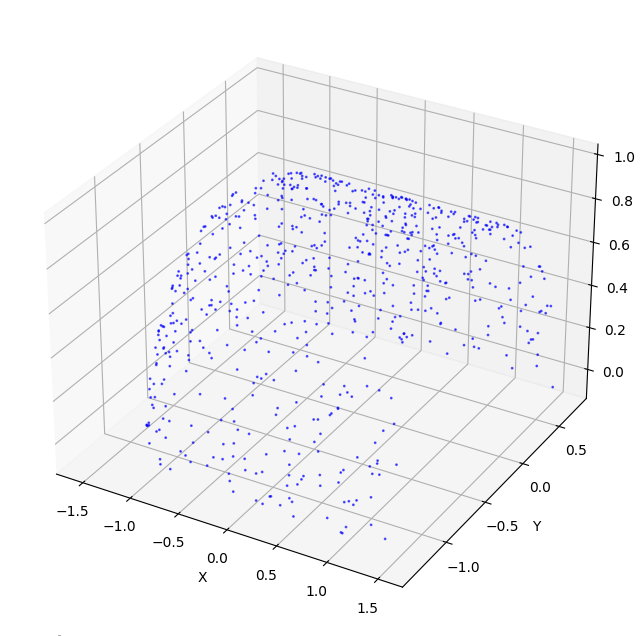

torch.Size([697, 3])


In [20]:
z_idx = xpts[:, 2].topk(int(0.35*xpts.shape[0]), largest=True).indices
final_pts = xpts[z_idx]
mask = final_pts[:, 0] < final_pts[:, 0].max()
final_pts = final_pts[mask]
visualize_point_cloud_matplotlib(final_pts)

print(final_pts.shape)

In [ ]:
def farthest_point_sampling_torch(points, n_samples, init_idx=None, return_distance=False):
    """
    points: torch.Tensor of shape (B, N, 3) or (N, 3), if batched then B>1
    n_samples: int, number of points to sample
    init_idx: optional initial point index, if None randomly choose
    return_distance: whether to return the final min distances
    returns: 
        if not batched: indices of shape (n_samples,)
        if batched: indices of shape (B, n_samples)
        optionally also returns min_distances
    """
    if len(points.shape) == 2:
        # 单批次情况 -> 增加批次维度以便统一处理
        points = points.unsqueeze(0)
        batch_mode = False
    else:
        batch_mode = True
    
    B, N, D = points.shape
    device = points.device
    
    # 初始化索引张量
    sampled_indices = torch.zeros(B, n_samples, dtype=torch.long, device=device)
    
    # 初始化最小距离平方为无穷大
    min_distances = torch.full((B, N), float('inf'), device=device)
    
    if init_idx is None:
        # 随机选第一个点
        tmp_idx = torch.randint(0, N, (B,), device=device)
    else:
        tmp_idx = init_idx
    
    # 第一个点
    sampled_indices[:, 0] = tmp_idx
    # 计算第一个点到所有点的距离平方
    last_points = points.gather(1, tmp_idx.view(B, 1, 1).expand(B, 1, D)).squeeze(1)
    dist_to_last = torch.sum((points - last_points.unsqueeze(1)) ** 2, dim=-1)  # (B, N)
    min_distances = torch.minimum(min_distances, dist_to_last)
    
    for i in range(1, n_samples):
        # 选择距离最大的点
        current_idx = torch.argmax(min_distances, dim=1)  # (B,)
        sampled_indices[:, i] = current_idx
        
        # 更新最小距离：计算当前选中的这些点到所有点的距离
        current_points = points.gather(1, current_idx.view(B, 1, 1).expand(B, 1, D)).squeeze(1)
        dist_to_current = torch.sum((points - current_points.unsqueeze(1)) ** 2, dim=-1)  # (B, N)
        min_distances = torch.minimum(min_distances, dist_to_current)
    
    if not batch_mode:
        sampled_indices = sampled_indices.squeeze(0)
        min_distances = min_distances.squeeze(0)
    
    if return_distance:
        return sampled_indices, min_distances
    else:
        return sampled_indices